# Plot color palette for dark and light mode

In [1]:

import matplotlib.pyplot as plt

PLOT_COLORS = {
    "light": [
        "#1762A0", "#A64600", "#006D69",
        "#7840A4", "#886000"
    ],
    "dark": [
        "#67B4F2", "#FFAB66", "#53D5C3",
        "#C39BF5", "#F4D45D"
    ]
}

LINESTYLES = ["-", "--", ":", "-.", (0, (8, 3))]
MARKERS = ["o", "s", "^", "D", "x"]

def setup_plot(mode="light"):
    dark = mode == "dark"
    bg = "#17191F" if dark else "#FFFFFF"
    fg = "#F0F0F0" if dark else "#202020"

    plt.rcParams.update({
        "figure.facecolor": bg,
        "axes.facecolor": bg,
        "savefig.facecolor": bg,
        "text.color": fg,
        "axes.labelcolor": fg,
        "xtick.color": fg,
        "ytick.color": fg,
        "axes.edgecolor": fg,
        "grid.alpha": 0.18,
        "axes.prop_cycle": plt.cycler(
            color=PLOT_COLORS[mode]
        )
    })

    return PLOT_COLORS[mode]

# Plot Setup
colors = setup_plot("dark")

# Für mehrere Messreihen:
# ax.plot(x, y, color=colors[i],
#         linestyle=LINESTYLES[i],
#         marker=MARKERS[i])


# Task 3
Implement numerical integrator that evolves $$(p_0, \phi_0)\rightarrow(p_f, \phi_f)$$ over MD trajectory of total length 1, using $N_{md}$ steps with step size $$\varepsilon = \frac{1}{N_{md}}.$$

Verify $$H(p_f,\phi_f) = H(p_0,\phi_0)+\mathcal{O}(\varepsilon^2) - \text{rel. Hamiltonian error}$$ with $$\frac{H(p_f,\phi_f)-H(p_0,\phi_0)}{H(p_0,\phi_0)}$$ as seen in Fig.1.

## Leapfrog algorithm
```mermaid

flowchart LR
    A["Initialize: (Π, Φ) = (p₀, Φ₀)"]
    B["Half position step:
    Φ → Φ + (ε/2)Π"]
    C["Repeat N_md − 1 times:
    Π → Π + ε F(Φ)
    Φ → Φ + εΠ"]
    D["Final momentum and position steps:
    Π → Π + ε F(Φ)
    Φ → Φ + (ε/2)Π"]

    A --> B
    B --> C
    C --> D

```
with $\dot{\phi}=p$ and $\dot{p} = F(\phi)$

In [2]:
import numpy as np

def hmc_hamiltonian(p, phi, N, beta, J_hat, h):
    """Calc the artificial HMC Hamiltonian"""

    kinetic = 0.5 * (p ** 2)
    potential = 0.5 * phi**2/ (beta * J_hat) - N * np.log(2*np.cosh(beta * h + phi))

    return kinetic + potential

def force(phi, N, beta, J_hat, h):
    """Calc dp/dt from Hamiltonian"""

    return -phi / (beta * J_hat) + N * np.tanh(beta * h + phi)

def leapfrog(p0, phi0, N_md, N, beta, J_hat, h, tau=1.0):
    """Integrate Hamilton equations over a trajectory of length 1"""

    if N_md < 1:
        raise ValueError("N_md must be >= 1")
    # epsilon = 1.0 / N_md
    epsilon = tau / N_md

    Pi = float(p0)
    Phi = float(phi0)

    # first half position step
    Phi += 0.5 * epsilon * Pi

    # N_md -1 full steps
    for _ in range(N_md - 1):
        Pi += epsilon * force(Phi, N, beta, J_hat, h)
        Phi += epsilon * Pi

    # Final momentum step
    Pi += epsilon * force(Phi, N, beta, J_hat, h)

    # Final half position step
    Phi += 0.5 * epsilon * Pi

    return Pi, Phi

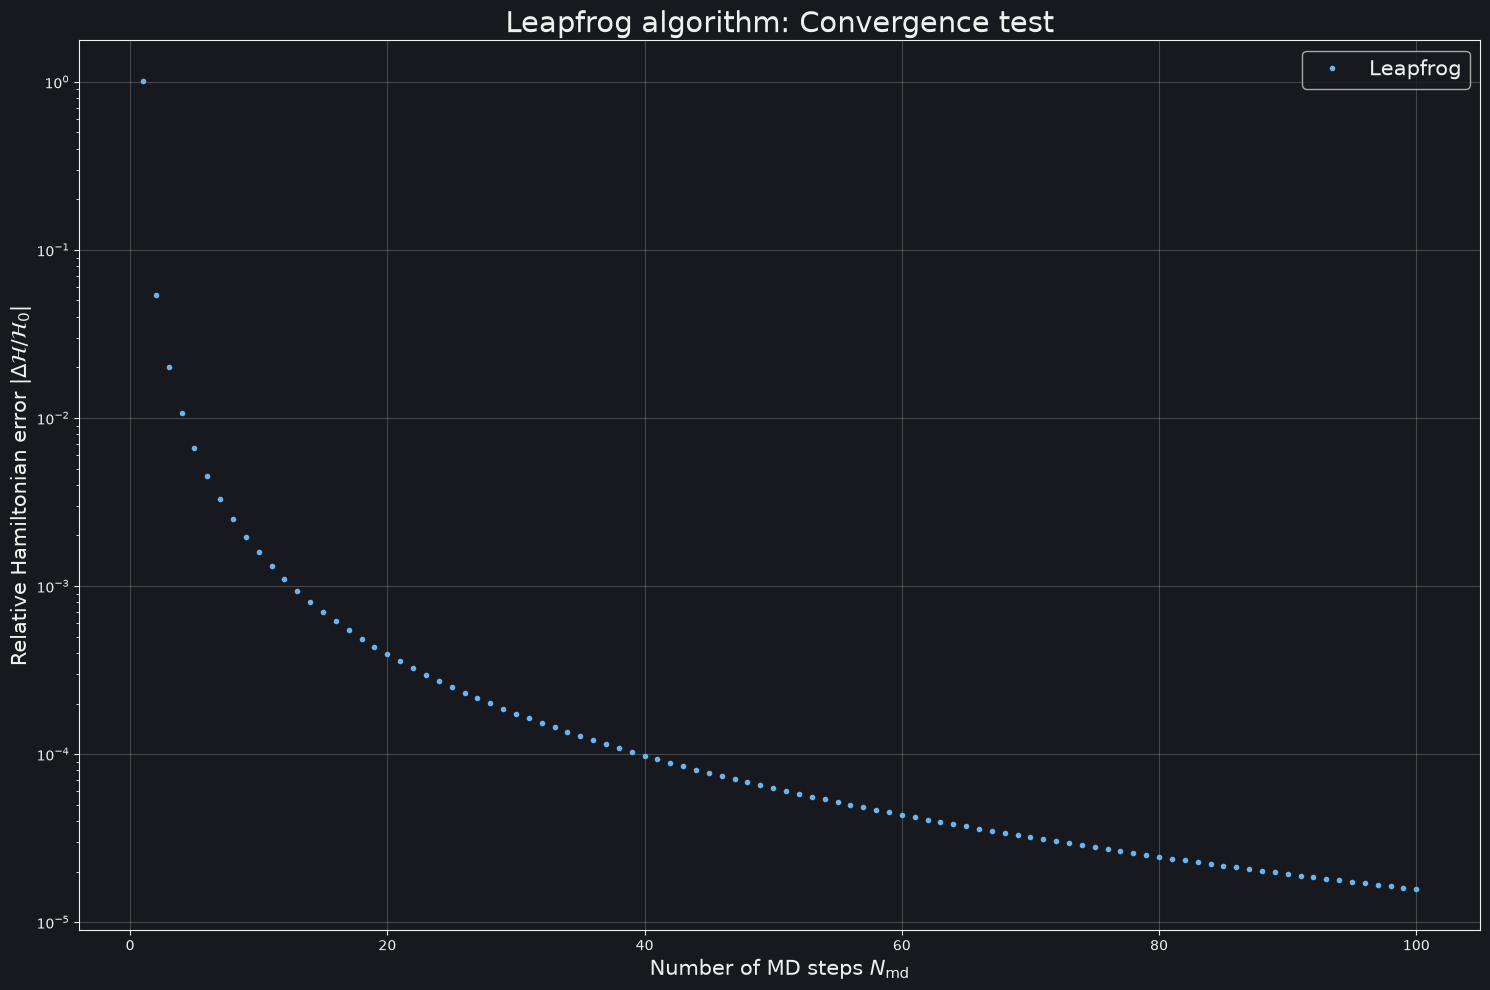

In [3]:
# ============================================================
# Task 3: Testing leapfrog convergence

N = 10
beta = 1.0
J = 1.0
J_hat = J / N
h = 0.5

# fixed init conditions
p0 = 0.7
phi0 = 0.2

N_md_values = np.arange(1, 101)  # Number of leapfrog steps to test

# Initial hamiltonian
H0 = hmc_hamiltonian(p0, phi0, N, beta, J_hat, h)

relative_errors = []

for N_md in N_md_values:
    # evolve using leapfrog
    pf, phif = leapfrog(p0, phi0, N_md, N, beta, J_hat, h)
    #calc final hamiltonian
    Hf = hmc_hamiltonian(pf, phif, N, beta, J_hat, h)
    relative_error = abs(Hf - H0) / abs(H0)
    relative_errors.append(relative_error)

# Plotting the results
fig, ax = plt.subplots(figsize=(15, 10))

# Relative Hamiltonian error
ax.plot(
    N_md_values,
    relative_errors,
    marker="o",
    markersize=3,
    linestyle="none",
    label="Leapfrog",
    color=colors[0]
)

ax.set_yscale("log")

ax.set_xlabel(r"Number of MD steps $N_{\mathrm{md}}$", fontsize=15)
ax.set_ylabel(r"Relative Hamiltonian error $|\Delta\mathcal{H}/\mathcal{H}_0|$", fontsize=15)
ax.set_title("Leapfrog algorithm: Convergence test", fontsize=21)

ax.grid(alpha=0.3)
ax.legend(fontsize=15)

plt.tight_layout()
plt.savefig("figs/leapfrog_convergence_test.pdf", dpi=300)
plt.show()


With $H(p_f,\phi_f) = H(p_0,\phi_0) + \mathcal{O}(\epsilon^2)$ and fixed trajectory length fixed at 1 $\varepsilon = \frac{1}{N_{md}}$ we expect for sufficiently large $N_{md}$: $$\frac{|\Delta H|}{|H_0|}\approx\frac{A}{N_{md}^2}$$ for some constant $A$.

To verify we take the logarithm: $$\ln\left(\frac{|\Delta H|}{|H_0|}\right)\approx\ln(A)-2\ln(N_{md}).$$ This has the form of a straight line $$y = mx+b$$ with an expected slope of $m\approx -2$

Measured convergence slope: -2.0014
Expected convergence slope: -2.0000


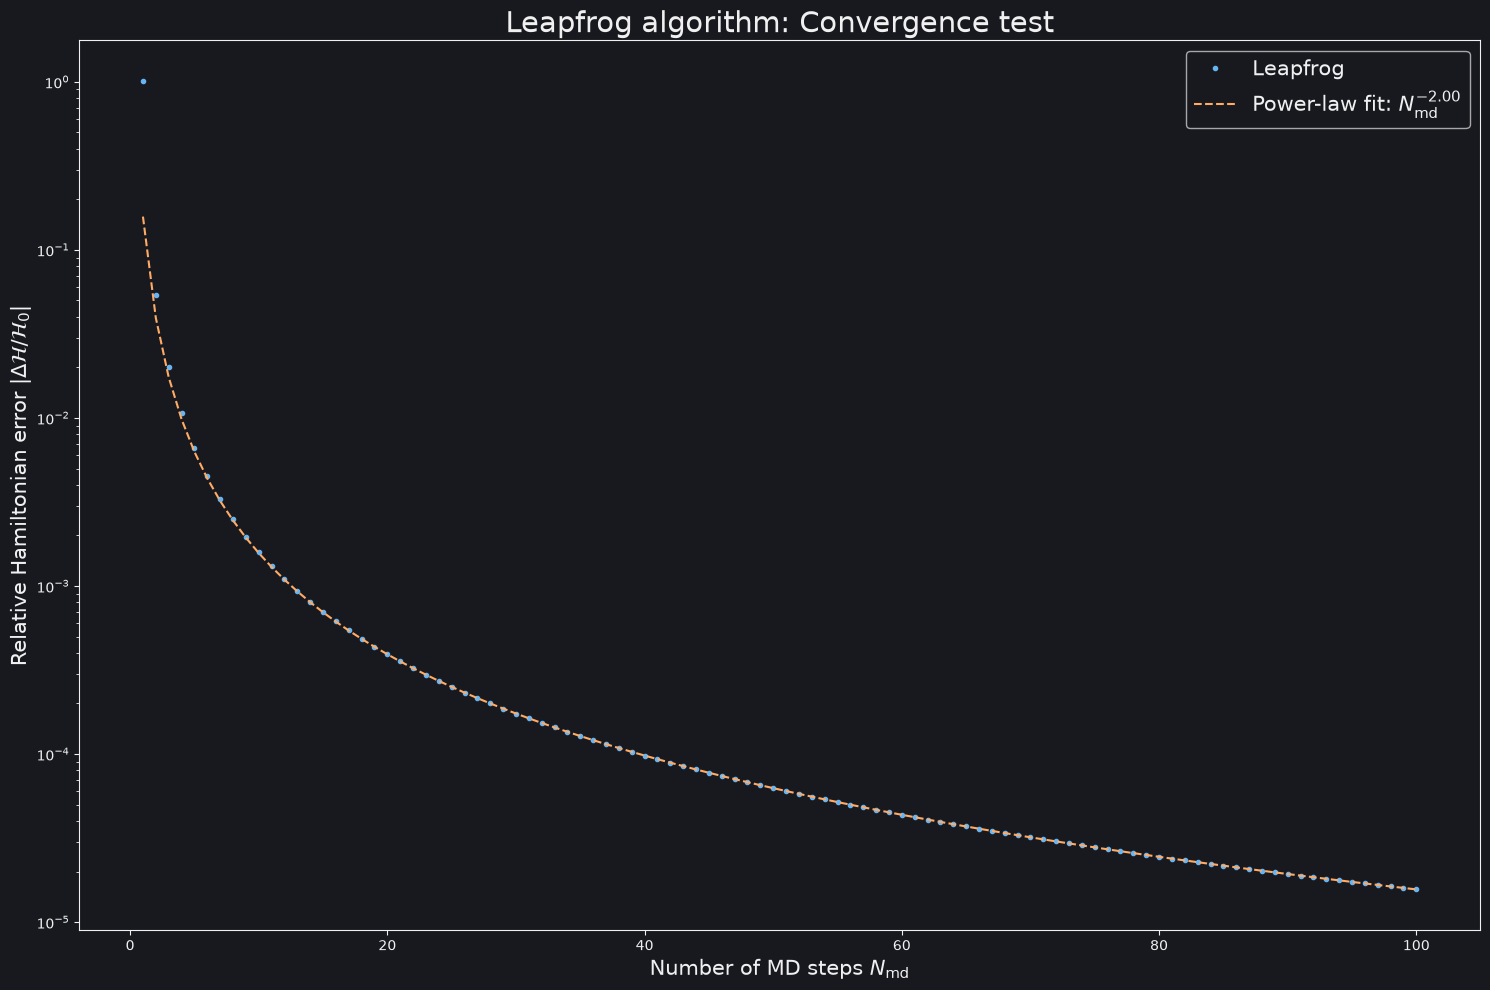

In [4]:
# Check second-order convergence using a log-log fit

errors = np.array(relative_errors)

# Use larger N_md values to avoid the coarse-step regime
mask = N_md_values >= 20

slope, intercept = np.polyfit(
    np.log(N_md_values[mask]),
    np.log(errors[mask]),
    1
)

print(f"Measured convergence slope: {slope:.4f}")
print("Expected convergence slope: -2.0000")

fig, ax = plt.subplots(figsize=(15, 10))
# Relative Hamiltonian error
ax.plot(
    N_md_values,
    relative_errors,
    marker="o",
    markersize=3,
    linestyle="none",
    label="Leapfrog",
    color=colors[0]
)

ax.plot(
    N_md_values,
    np.exp(intercept) * N_md_values**slope,
    linestyle="--",
    label=rf"Power-law fit: $N_{{\mathrm{{md}}}}^{{{slope:.2f}}}$",
    color=colors[1]
)
ax.set_yscale("log")
ax.set_xlabel(r"Number of MD steps $N_{\mathrm{md}}$", fontsize=15)
ax.set_ylabel(r"Relative Hamiltonian error $|\Delta\mathcal{H}/\mathcal{H}_0|$", fontsize=15)
ax.set_title("Leapfrog algorithm: Convergence test", fontsize=21)
ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig("figs/leapfrog_convergence_test_fit.pdf", dpi=300)
plt.show()



# Task 4 Implementing HMC

With working leapfrog integrator, implement HMV algorithm for long-range Ising model.

## HMC Iterations
```mermaid

flowchart LR
    A["Start with some initial field Φ"]
    B["Draw/Sample fresh momentum 
    p ∈ N(0,1)"]
    C["Integrate EoMs using leapfrog to propose (p',Φ')"]
    D["Calculate 
    ΔH = H(p',Φ') 
    - H(p,Φ)"]
    E["Accept proposal?"]
    F["Φₙₑᵥ = Φ'"]
    G["Φₙₑᵥ = Φ"]

    A --> B --> C --> D --> E
    E -->|Yes| F
    E -->|No| G
```

In [5]:
def hmc_step(phi, N_md, N, beta, J_hat, h, rng):
    """Perform one HMC update of the field phi"""

    # Sample fresh momentum from standard normal distribution
    p0 = rng.normal(0, 1)

    # calc initial Hamiltonian
    H0 = hmc_hamiltonian(p0, phi, N, beta, J_hat, h)

    # propose new state using leapfrog integration
    # pf, phif = leapfrog(p0, phi, N_md, N, beta, J_hat, h)
    tau = rng.uniform(0.5, 1.5) # randomize trajectory length
    pf, phif = leapfrog(p0, phi, N_md, N, beta, J_hat, h, tau=tau)

    # calc final Hamiltonian
    Hf = hmc_hamiltonian(pf, phif, N, beta, J_hat, h)

    # Hamiltonian difference
    dH = Hf - H0 

    # Metropolis acceptance step
    if dH <= 0 or rng.random() < np.exp(-dH):
        return phif, True  # accept
    
    return phi, False  # reject

def run_hmc(phi0, N_md, N, beta, J_hat, h, n_therm, n_meas, rng):
    """Run a HMC sim and return field samples and acceptance rate"""

    phi = float(phi0)

    # Thermalization
    for _ in range(n_therm):
        phi, accepted = hmc_step(phi, N_md, N, beta, J_hat, h, rng)

    # Measurement phase
    phi_samples = np.empty(n_meas)
    n_accepted = 0

    for i in range(n_meas):
        phi, accepted = hmc_step(phi, N_md, N, beta, J_hat, h, rng)

        # Store the sample and count acceptance
        phi_samples[i] = phi
        n_accepted += int(accepted)

    acceptance_rate = n_accepted / n_meas

    return phi_samples, acceptance_rate

Acceptance rate: 99.88%
Mean of phi samples: 0.8387
Std of phi samples: 0.3781


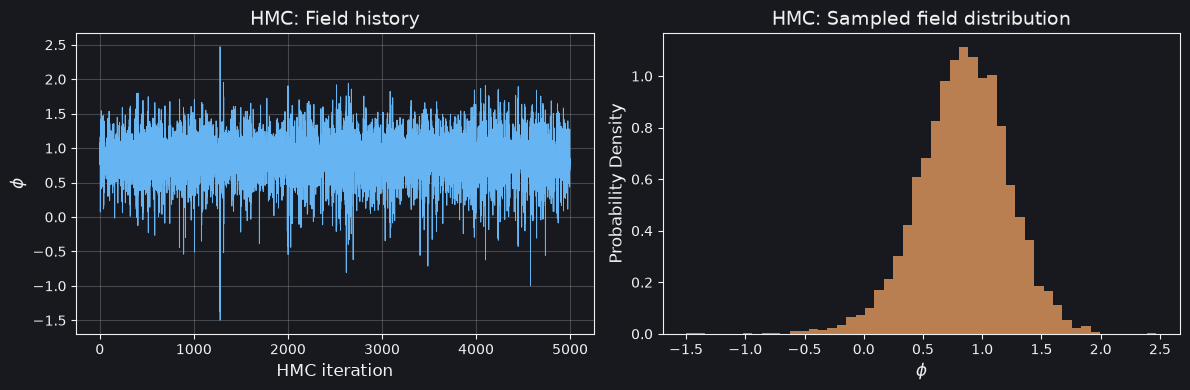

In [14]:
# ============================================================
# Task 4: Test complete HMC algo

N = 10
beta = 1.0
J = 1.0
J_hat = J / N
h = 0.5

N_md = 20

phi0 = 0.0
n_therm = 1000
n_meas = 5000

rng = np.random.default_rng(seed=42)


phi_samples, acceptance_rate = run_hmc(
    phi0=phi0,
    N_md=N_md,
    N=N,
    beta=beta,
    J_hat=J_hat,
    h=h,
    n_therm=n_therm,
    n_meas=n_meas,
    rng=rng
)

print(f"Acceptance rate: {acceptance_rate:.2%}")
print(f"Mean of phi samples: {np.mean(phi_samples):.4f}")
print(f"Std of phi samples: {np.std(phi_samples):.4f}")

# Plot histogram of phi samples
fig, axes = plt.subplots(1,2,figsize=(12, 4))

# Markov chain history
axes[0].plot(phi_samples, color=colors[0], linewidth=0.7)
axes[0].set_xlabel("HMC iteration", fontsize=12)
axes[0].set_ylabel(r"$\phi$", fontsize=12)
axes[0].set_title("HMC: Field history", fontsize=14)
axes[0].grid(alpha=0.3)

# Distribution of phi samples
axes[1].hist(phi_samples, bins=50, density=True, color=colors[1], alpha=0.7)
axes[1].set_xlabel(r"$\phi$", fontsize=12)
axes[1].set_ylabel("Probability Density", fontsize=12)
axes[1].set_title("HMC: Sampled field distribution", fontsize=14)
plt.tight_layout()
plt.savefig("figs/hmc_field_samples.pdf", dpi=300)  
plt.show()

# Task 5
Calculate $\langle m \rangle$ and $\langle\varepsilon\rangle$ for different values of $N \in [5,20]$ and $J = (\beta J)\in [0.2,2]$ while keeping $\beta h = 0.5$. Tune $N_{md}$ so that the acceptance rate is $r_{acc}>50\%$.

In [7]:
def magnetization_observable(phi_samples, beta, h):
    """Magnetization per site for each sampled phi value"""
    return np.tanh(beta * h + phi_samples)

def energy_observable(phi_samples, N, beta, J_hat, h):
    """Energy per site for each sampled phi value."""
    return (
        1 / (2 * N * beta)
        - phi_samples**2 / (2 * N * beta**2 * J_hat)
        - h * np.tanh(beta * h + phi_samples)
    )

In [8]:
# ============================================================
# Task 5: Test magnetization and energy observables

from math import comb

# Calc observables for the sampled phi values
m_measurements = magnetization_observable(phi_samples, beta, h)
E_measurements = energy_observable(phi_samples, N, beta, J_hat, h)

# calc mean observables
mean_m = np.mean(m_measurements)
mean_E = np.mean(E_measurements)

print(f"Mean magnetization per site: {mean_m:.6f}")
print(f"Mean energy per site: {mean_E:.6f}")
print(f"HMC acceptance rate: {acceptance_rate:.2%}")

def exact_ising_observables(N, beta, J, h):
    """Exact finite-N magnetization and energy per site."""

    J_hat = J / N

    # Number of downward spins
    n = np.arange(N + 1)

    # Total spin for each possible n
    s = N - 2 * n

    # Number of configurations with n downward spins
    degeneracy = np.array(
        [comb(N, int(k)) for k in n],
        dtype=float
    )

    # Boltzmann weights including degeneracy
    weights = degeneracy * np.exp(
        0.5 * beta * J_hat * s**2 + beta * h * s
    )

    # Partition function
    Z = np.sum(weights)

    # Exact mean magnetization per site
    mean_m = np.sum(weights * s) / Z / N

    # Exact mean energy per site
    mean_E = -np.sum(weights * (0.5 * J_hat * s**2 + h * s)) / Z / N

    return mean_m, mean_E

exact_mean_m, exact_mean_E = exact_ising_observables(
    N=10, 
    beta=1.0, 
    J=1.0, 
    h=0.5)
print(f"Exact mean magnetization per site: {exact_mean_m:.6f}")
print(f"Exact mean energy per site: {exact_mean_E:.6f}")

Mean magnetization per site: 0.839783
Mean energy per site: -0.793096
HMC acceptance rate: 99.88%
Exact mean magnetization per site: 0.839506
Exact mean energy per site: -0.794282


In [9]:
# ============================================================
# Task 5: Full parameter scan

N_vals = [5, 10, 15, 20]
beta_J_vals = np.linspace(0.2, 2.0, 20)

beta = 1.0
beta_h = 0.5
h = beta_h / beta  # Adjust h to keep beta*h constant

N_md = 20
n_therm = 1000
n_meas = 5000

rng = np.random.default_rng(seed=42)

results = {}

for N in N_vals:

    mean_m_vals = []
    mean_E_vals = []
    exact_m_vals = []
    exact_E_vals = []
    acceptance_rates = []

    for beta_J in beta_J_vals:
        J = beta_J / beta  # convert dimensionless coupling to physical coupling
        J_hat = J / N

        # Run HMC simulation
        phi_samples, acceptance_rate = run_hmc(
            phi0=0.0,
            N_md=N_md,
            N=N,
            beta=beta,
            J_hat=J_hat,
            h=h,
            n_therm=n_therm,
            n_meas=n_meas,
            rng=rng
        )

        # Calculate observables
        mean_m = np.mean(magnetization_observable(phi_samples, beta, h))
        mean_E = np.mean(energy_observable(phi_samples, N, beta, J_hat, h))

        # Exact results
        exact_mean_m, exact_mean_E = exact_ising_observables(N, beta, J, h)

        # Store results
        mean_m_vals.append(mean_m)
        mean_E_vals.append(mean_E)
        exact_m_vals.append(exact_mean_m)
        exact_E_vals.append(exact_mean_E)
        acceptance_rates.append(acceptance_rate)

    results[N] = {
        "mean_m": np.array(mean_m_vals),
        "mean_E": np.array(mean_E_vals),
        "exact_m": np.array(exact_m_vals),
        "exact_E": np.array(exact_E_vals),
        "acceptance_rates": np.array(acceptance_rates)
    }

    print(
        f"N={N:2d} | "
        f"min acceptance: {min(acceptance_rates):.2%} | "
        f"max acceptance: {max(acceptance_rates):.2%}"
    )
    

N= 5 | min acceptance: 99.68% | max acceptance: 99.98%
N=10 | min acceptance: 99.52% | max acceptance: 99.98%
N=15 | min acceptance: 99.10% | max acceptance: 99.94%
N=20 | min acceptance: 98.88% | max acceptance: 99.98%


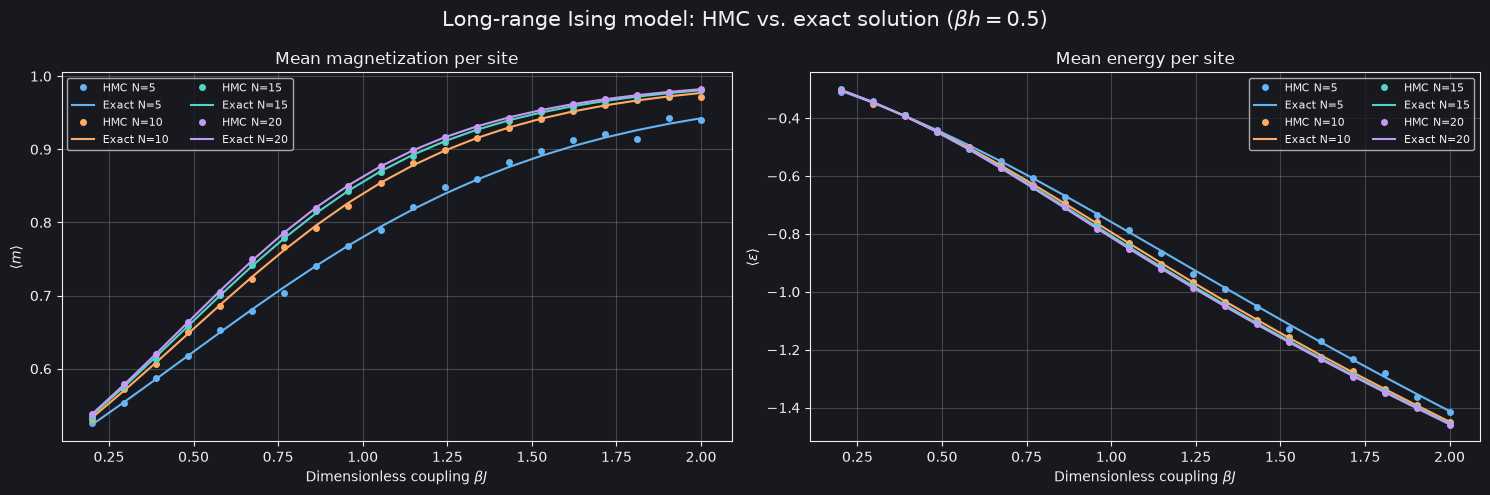

In [12]:
# ============================================================
# Task 5: HMC vs. exact finite-N results

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for N in N_vals:

    # Use the same color for HMC and exact results
    color = colors[N_vals.index(N)]

    # Magnetization: HMC measurements
    axes[0].plot(
        beta_J_vals,
        results[N]["mean_m"],
        marker="o",
        linestyle="none",
        markersize=4,
        color=color,
        label=f"HMC N={N}"
    )

    # Magnetization: exact finite-N solution
    axes[0].plot(
        beta_J_vals,
        results[N]["exact_m"],
        linestyle="-",
        linewidth=1.5,
        color=color,
        label=f"Exact N={N}"
    )

    # Energy: HMC measurements
    axes[1].plot(
        beta_J_vals,
        results[N]["mean_E"],
        marker="o",
        linestyle="none",
        markersize=4,
        color=color,
        label=f"HMC N={N}"
    )

    # Energy: exact finite-N solution
    axes[1].plot(
        beta_J_vals,
        results[N]["exact_E"],
        linestyle="-",
        linewidth=1.5,
        color=color,
        label=f"Exact N={N}"
    )

axes[0].set_title("Mean magnetization per site")
axes[0].set_xlabel(r"Dimensionless coupling $\beta J$")
axes[0].set_ylabel(r"$\langle m\rangle$")

axes[1].set_title("Mean energy per site")
axes[1].set_xlabel(r"Dimensionless coupling $\beta J$")
axes[1].set_ylabel(r"$\langle\epsilon\rangle$")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

fig.suptitle(
    r"Long-range Ising model: HMC vs. exact solution ($\beta h=0.5$)",
    fontsize=15
)

plt.tight_layout()
plt.savefig("figs/hmc_vs_exact.pdf", dpi=300)
plt.show()

In [11]:
# ============================================================
# Test HMC with randomized trajectory length

N = 20
beta = 1.0
beta_J = 0.3894736842
J = beta_J / beta
J_hat = J / N
h = 0.5

rng_test = np.random.default_rng(123)

phi_test, acc_test = run_hmc(
    phi0=0.0,
    N_md=20,
    N=N,
    beta=beta,
    J_hat=J_hat,
    h=h,
    n_therm=1000,
    n_meas=5000,
    rng=rng_test
)

# HMC observables
mean_m = np.mean(
    magnetization_observable(phi_test, beta, h)
)

mean_E = np.mean(
    energy_observable(phi_test, N, beta, J_hat, h)
)

# Exact observables
exact_m, exact_E = exact_ising_observables(
    N, beta, J, h
)

# Autocorrelation
rho1 = np.corrcoef(phi_test[:-1], phi_test[1:])[0, 1]

print(f"Acceptance rate:   {acc_test:.2%}")
print(f"Lag-1 correlation: {rho1:.6f}")
print()
print(f"HMC magnetization:   {mean_m:.6f}")
print(f"Exact magnetization: {exact_m:.6f}")
print()
print(f"HMC energy:          {mean_E:.6f}")
print(f"Exact energy:        {exact_E:.6f}")

Acceptance rate:   99.36%
Lag-1 correlation: 0.026640

HMC magnetization:   0.619125
Exact magnetization: 0.620695

HMC energy:          -0.391061
Exact energy:        -0.393139
